# 3b. Why is the harmonized series higher before 2012?

The harmonized series (`scripts/harmonize.py`) averages about 274k VIIRS-equivalent hotspots a year in
2001-2011 and 204k in 2013-2025, a ratio of 1.35 (`docs/findings/eda-summary-and-harmonization.md`, 2.4).
This notebook runs the checks proposed there:

- **A.** Harmonize with Terra only and with Aqua only (2003-2011) and see whether they agree.
- **B.** Move the calibration window and the shrinkage constant `K` and see how much the level moves.
- **C.** Repeat with fire-days (0.25° cell and day with at least one hotspot), and compare MODIS with
  itself across 2012, without any factor.
- **D.** See which regions and months hold the higher level.
- **E.** (extra) Look for static sources that only existed before 2012.
- **F.** (extra) Measure how much the reference median of the app depends on which years enter it.

Input: `processed/harmonized/hotspots_kept.parquet` (pipeline step 7). Nothing is written to disk except
the summary figure `docs/findings/03b-pre2012-level.png`.

In [1]:
import math
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.width', 200)
ROOT = Path.cwd().resolve()
if not (ROOT / 'scripts').exists():
    ROOT = ROOT.parent
KEPT = (ROOT / 'NASA_Data_Sources' / 'processed' / 'harmonized' / 'hotspots_kept.parquet').as_posix()

con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
con.execute(f'''CREATE TABLE h AS
  SELECT burn_date, burn_year, burn_month, pass_slot, country, admin1, satellite, instrument,
         floor(latitude * 4) / 4 AS clat, floor(longitude * 4) / 4 AS clon,
         burn_date < DATE '2002-07-04' AS pre_aqua
  FROM read_parquet('{KEPT}')
  WHERE burn_year <= 2025 AND satellite IN ('Terra', 'Aqua', 'Suomi-NPP')''')

# Monthly counts per sensor group, region and pass, in two units:
#   rows      one hotspot = 1, per pass (as in harmonize.py)
#   firedays  distinct (0.25° cell, burn_date, region) with at least one hotspot of the group; no pass
GROUPS = {'viirs': "satellite = 'Suomi-NPP'", 'terra': "satellite = 'Terra'",
          'aqua': "satellite = 'Aqua'", 'modis': "instrument = 'MODIS'"}
parts = []
for g, cond in GROUPS.items():
    parts.append(f'''SELECT 'rows' unit, '{g}' grp, country, admin1, burn_year, burn_month, pass_slot slot, pre_aqua,
                       count(*)::DOUBLE n FROM h WHERE {cond} GROUP BY ALL''')
    parts.append(f'''SELECT 'firedays' unit, '{g}' grp, country, admin1, burn_year, burn_month, 'all' slot, pre_aqua,
                       count(*)::DOUBLE n
                     FROM (SELECT DISTINCT clat, clon, burn_date, country, admin1, burn_year, burn_month, pre_aqua
                           FROM h WHERE {cond}) GROUP BY ALL''')
_ = con.execute('CREATE TABLE u AS ' + ' UNION ALL '.join(parts))

In [2]:
def harmonized(unit='rows', grp='modis', cal=(2012, 2021), K=200.0, by='burn_year'):
    """The harmonized series with one set of choices, summed by `by`.

    Same method as scripts/harmonize.py: before February 2012 the MODIS group `grp` is scaled with
    factor (V + K * country_factor) / (M + K) per region, calendar month and slot, fitted on the
    calibration years; rows without region (or regions without calibration data) use the country
    factor. For grp='modis', rows before Aqua use Terra-only factors. From February 2012, Suomi-NPP
    unchanged. K=0 is the raw regional ratio; K=inf is the country factor alone.
    """
    y0, y1 = cal
    calw = f'burn_year BETWEEN {y0} AND {y1} AND NOT (burn_year = 2012 AND burn_month = 1)'
    k = 'NULL' if math.isinf(K) else str(float(K))
    q = f"""
    WITH c AS (SELECT * FROM u WHERE unit = '{unit}' AND {calw}),
    cf AS (SELECT m.grp, m.country, m.burn_month, m.slot, v.n / m.n AS cf FROM
             (SELECT grp, country, burn_month, slot, sum(n) n FROM c WHERE grp <> 'viirs' GROUP BY ALL) m
             JOIN (SELECT country, burn_month, slot, sum(n) n FROM c WHERE grp = 'viirs' GROUP BY ALL) v
             USING (country, burn_month, slot)),
    cf0 AS (SELECT m.grp, m.country, v.n / m.n AS cf0 FROM
             (SELECT grp, country, sum(n) n FROM c WHERE grp <> 'viirs' GROUP BY ALL) m
             JOIN (SELECT country, sum(n) n FROM c WHERE grp = 'viirs' GROUP BY ALL) v USING (country)),
    rf AS (SELECT m.grp, m.country, m.admin1, m.burn_month, m.slot, m.n AS mn, coalesce(v.n, 0) AS vn FROM
             (SELECT grp, country, admin1, burn_month, slot, sum(n) n FROM c
              WHERE grp <> 'viirs' AND admin1 IS NOT NULL GROUP BY ALL) m
             LEFT JOIN (SELECT country, admin1, burn_month, slot, sum(n) n FROM c WHERE grp = 'viirs' GROUP BY ALL) v
             USING (country, admin1, burn_month, slot)),
    src AS (SELECT *, CASE WHEN pre_aqua AND '{grp}' = 'modis' THEN 'terra' ELSE '{grp}' END AS fgrp FROM u
            WHERE unit = '{unit}' AND grp = '{grp}' AND (burn_year < 2012 OR (burn_year = 2012 AND burn_month = 1))),
    m AS (SELECT s.country, s.admin1, s.burn_year, s.burn_month, s.n AS raw,
                 s.n * coalesce(CASE WHEN {k} IS NULL THEN NULL
                                     ELSE (rf.vn + {k} * cf.cf) / nullif(rf.mn + {k}, 0) END,
                                cf.cf, cf0.cf0) AS harm,
                 cf.cf IS NULL AS fallback
          FROM src s
          LEFT JOIN cf ON cf.grp = s.fgrp AND cf.country = s.country AND cf.burn_month = s.burn_month AND cf.slot = s.slot
          LEFT JOIN cf0 ON cf0.grp = s.fgrp AND cf0.country = s.country
          LEFT JOIN rf ON rf.grp = s.fgrp AND rf.country = s.country AND rf.admin1 = s.admin1
                      AND rf.burn_month = s.burn_month AND rf.slot = s.slot),
    v AS (SELECT country, admin1, burn_year, burn_month, n AS raw, n AS harm, false AS fallback FROM u
          WHERE unit = '{unit}' AND grp = 'viirs' AND NOT (burn_year = 2012 AND burn_month = 1))
    SELECT {by}, sum(harm) AS harm, sum(fallback::INT) AS n_fallback
    FROM (SELECT * FROM m UNION ALL SELECT * FROM v) GROUP BY ALL ORDER BY ALL"""
    return con.execute(q).df()


def level(df, early=(2001, 2011), late=(2013, 2025)):
    """Mean of the early years over mean of the late years (2012 is a mixed year and stays out)."""
    s = df.set_index('burn_year').harm
    return s.loc[early[0]:early[1]].mean() / s.loc[late[0]:late[1]].mean()


base = harmonized()
s = base.set_index('burn_year').harm
print(f"mean 2001-2011: {s.loc[2001:2011].mean():,.0f} | mean 2013-2025: {s.loc[2013:2025].mean():,.0f} "
      f"| level ratio {level(base):.3f}")
print(f"median ratio: {s.loc[2001:2011].median() / s.loc[2013:2025].median():.3f} "
      f"| mean ratio without 2020: {s.loc[2001:2011].mean() / s.loc[2013:2025].drop(2020).mean():.3f}")
official = con.execute(f"""SELECT year(burn_date) burn_year, sum(hotspots_harmonized) harm
    FROM read_parquet('{(ROOT / 'NASA_Data_Sources/processed/harmonized/cells_daily.parquet').as_posix()}')
    WHERE year(burn_date) BETWEEN 2001 AND 2025 GROUP BY 1""").df().set_index('burn_year').harm
print('largest yearly difference against cells_daily.parquet (%):',
      round(100 * ((s.loc[2001:2025] / official.sort_index()) - 1).abs().max(), 3))

mean 2001-2011: 273,820 | mean 2013-2025: 203,561 | level ratio 1.345
median ratio: 1.468 | mean ratio without 2020: 1.474
largest yearly difference against cells_daily.parquet (%): 0.031


The function reproduces `cells_daily.parquet`: the VIIRS years match exactly and the MODIS years within a
few hundredths of a percent (border cells and rounding). Without 2020, or with medians, the ratio is
larger (about 1.47), so it is not driven by one extreme VIIRS year.

## A. Terra only against Aqua only, 2003-2011

Terra (morning pass) and Aqua (afternoon pass) are two separate instruments with their own factors. If
they give the same harmonized years, the factors are not specific to one satellite or one pass time.

In [3]:
A = {(g, unit): harmonized(unit, g).set_index('burn_year').harm
     for g in ['modis', 'terra', 'aqua'] for unit in ['rows', 'firedays']}
ta = pd.DataFrame({'Terra rows': A[('terra', 'rows')], 'Aqua rows': A[('aqua', 'rows')],
                   'Terra fire-days': A[('terra', 'firedays')], 'Aqua fire-days': A[('aqua', 'firedays')]}).loc[2003:2011]
ta['Terra / Aqua rows'] = ta['Terra rows'] / ta['Aqua rows']
ta['Terra / Aqua fire-days'] = ta['Terra fire-days'] / ta['Aqua fire-days']
display(ta.round(2))
lv = pd.DataFrame([dict(group=g, unit=unit, **{'2003-11 / 2013-25': level(A[(g, unit)].reset_index(), (2003, 2011)),
                                               '2003-11 / 2013-21': level(A[(g, unit)].reset_index(), (2003, 2011), (2013, 2021))})
                   for (g, unit) in A]).round(3)
display(lv)

,Terra rows,Aqua rows,Terra fire-days,Aqua fire-days,Terra / Aqua rows,Terra / Aqua fire-days
burn_year,,,,,,
2003,350348.10,378353.57,71922.19,79793.72,0.93,0.90
2004,325166.98,325957.26,74184.30,76821.06,1.00,0.97
2005,239066.61,229285.22,57209.00,57822.08,1.04,0.99
2006,268040.69,265706.72,66344.55,65308.52,1.01,1.02
2007,253067.61,251235.55,57983.80,59824.68,1.01,0.97
2008,358721.85,346832.70,82889.71,77353.51,1.03,1.07
2009,279809.62,279094.07,62310.99,58931.41,1.00,1.06
2010,199423.79,205878.76,48182.93,50503.36,0.97,0.95
2011,256508.42,255118.46,56554.57,55974.34,1.01,1.01


,group,unit,2003-11 / 2013-25,2003-11 / 2013-21
0,modis,rows,1.370,1.355
1,modis,firedays,1.363,1.327
2,terra,rows,1.381,1.366
3,terra,firedays,1.375,1.339
4,aqua,rows,1.385,1.370
5,aqua,firedays,1.387,1.350


## B. Sensitivity to the calibration window and to `K`

`K = 0` uses each region's raw ratio, `K = inf` only the country factor. Windows after 2021 cross the
orbit drift and are included only as a bracket.

In [4]:
rows = []
for cal in [(2012, 2021), (2012, 2014), (2012, 2016), (2013, 2019), (2017, 2021), (2019, 2021), (2012, 2025)]:
    for K in [0, 50, 200, 1000, math.inf]:
        for unit in ['rows', 'firedays']:
            d = harmonized(unit, 'modis', cal, K)
            rows.append(dict(unit=unit, window=f'{cal[0]}-{cal[1]}', K=K, level=level(d), fallback=int(d.n_fallback.sum())))
B = pd.DataFrame(rows)
display(B.pivot_table(index=['unit', 'window'], columns='K', values='level').round(3))
print('hotspot-months that needed a fallback factor:', B.fallback.sum())
print('range over every choice: rows', B[B.unit == 'rows'].level.agg(['min', 'max']).round(3).tolist(),
      '| fire-days', B[B.unit == 'firedays'].level.agg(['min', 'max']).round(3).tolist(),
      '| K >= 50 only:', B[B.K >= 50].level.agg(['min', 'max']).round(3).tolist())

K                   0.0     50.0    200.0   1000.0  inf   
unit     window                                           
firedays 2012-2014   1.435   1.365   1.354   1.359   1.377
         2012-2016   1.404   1.357   1.342   1.342   1.364
         2012-2021   1.341   1.315   1.303   1.299   1.324
         2012-2025   1.336   1.315   1.303   1.298   1.326
         2013-2019   1.374   1.344   1.333   1.332   1.354
         2017-2021   1.311   1.281   1.272   1.274   1.293
         2019-2021   1.314   1.270   1.261   1.265   1.282
rows     2012-2014   1.456   1.346   1.337   1.337   1.343
         2012-2016   1.428   1.353   1.344   1.346   1.356
         2012-2021   1.373   1.349   1.345   1.349   1.367
         2012-2025   1.384   1.365   1.361   1.364   1.378
         2013-2019   1.399   1.356   1.351   1.355   1.365
         2017-2021   1.380   1.352   1.352   1.360   1.376
         2019-2021   1.406   1.353   1.352   1.360   1.379

hotspot-months that needed a fallback factor: 0
range over every choice: rows [1.337, 1.456] | fire-days [1.261, 1.435] | K >= 50 only: [1.261, 1.379]


## C. MODIS against itself, and the stability of the VIIRS / MODIS ratio

No factor here. If MODIS alone is about 1.35 times higher in 2003-2011 than after 2012, the level
difference does not come from the factors. 2013-2017 is the cleanest comparison: same MODIS collection
(6.2, 2000-2017) and stable orbits (drift starts in 2022).

In [5]:
raw = con.execute("SELECT unit, grp, burn_year, sum(n) n FROM u GROUP BY ALL").df()
rw = raw.pivot_table(index='burn_year', columns=['unit', 'grp'], values='n')
out = []
for unit in ['rows', 'firedays']:
    for g in ['modis', 'terra', 'aqua']:
        x = rw[(unit, g)]
        out.append(dict(unit=unit, group=g, **{'2003-11 / 2013-17': x.loc[2003:2011].mean() / x.loc[2013:2017].mean(),
                                               '2003-11 / 2013-21': x.loc[2003:2011].mean() / x.loc[2013:2021].mean()}))
display(pd.DataFrame(out).round(3))

ratio = pd.DataFrame({u: rw[(u, 'viirs')] / rw[(u, 'modis')] for u in ['rows', 'firedays']}).loc[2013:2025]
display(ratio.T.round(2))
for u in ['rows', 'firedays']:
    y = ratio.loc[2013:2021, u]
    slope = np.polyfit(y.index, y.values, 1)[0]
    print(f'{u}: VIIRS / MODIS 2013-2021, slope {100 * slope / y.mean():+.2f}% of the mean per year, '
          f'coefficient of variation {100 * y.std() / y.mean():.1f}%')

,unit,group,2003-11 / 2013-17,2003-11 / 2013-21
0,rows,modis,1.514,1.352
1,rows,terra,1.478,1.335
2,rows,aqua,1.535,1.362
3,firedays,modis,1.486,1.326
4,firedays,terra,1.483,1.309
5,firedays,aqua,1.536,1.368


burn_year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
rows,3.31,3.11,3.21,3.09,3.11,3.10,2.93,3.40,3.12,3.69,3.19,2.82,3.28
firedays,2.00,2.07,2.00,1.89,1.82,1.93,1.88,1.82,1.96,1.96,1.92,1.73,1.97


rows: VIIRS / MODIS 2013-2021, slope -0.25% of the mean per year, coefficient of variation 4.4%
firedays: VIIRS / MODIS 2013-2021, slope -0.96% of the mean per year, coefficient of variation 4.5%


## D. Where and when is the higher level?

Excess = mean harmonized hotspots per year in 2003-2011 minus 2013-2025 (2001-2002 left out: Terra
only). Share of excess adds to 100% over all regions; negative means the region is higher after 2012.

In [6]:
r = harmonized(by='country, admin1, burn_year')
r = r[r.burn_year.between(2003, 2025) & (r.burn_year != 2012)]
r['period'] = np.where(r.burn_year <= 2011, 'early', 'late')
g = r.groupby(['country', 'admin1', 'period'], dropna=False).harm.sum().unstack()
g['early'] /= 9
g['late'] /= 13
g['ratio'] = g.early / g.late
g['excess'] = g.early - g.late
g['share of excess %'] = 100 * g.excess / g.excess.sum()
print(f'early {g.early.sum():,.0f} | late {g.late.sum():,.0f} | excess {g.excess.sum():,.0f} per year')
display(g.sort_values('excess', ascending=False).round(2).head(12))
display(g.sort_values('excess').round(2).head(6))
cty = g.groupby(level=0)[['early', 'late']].sum()
cty['ratio'] = cty.early / cty.late
display(cty.round(2))

early 278,883 | late 203,561 | excess 75,322 per year


period                            early      late  ratio    excess  share of excess %
country   admin1                                                                     
Argentina Santiago del Estero  43605.57  16990.46   2.57  26615.10              35.34
          Salta                37141.82  14750.08   2.52  22391.74              29.73
          Chaco                28193.18  17731.46   1.59  10461.71              13.89
          Entre Ríos           13855.31   8907.31   1.56   4948.00               6.57
          Misiones              9459.12   5131.00   1.84   4328.12               5.75
          Corrientes           23289.24  19698.15   1.18   3591.08               4.77
          Santa Fe             30247.84  27063.46   1.12   3184.38               4.23
          Córdoba               7863.56   4869.38   1.61   2994.18               3.98
          San Luis              6908.02   3943.69   1.75   2964.33               3.94
          Tucumán               6817.77   4260.62   1.60   2557.15               3.39
          Buenos Aires          8042.83   5924.85   1.36   2117.99               2.81
          Catamarca             2638.39   1258.54   2.10   1379.85               1.83

period                               early      late  ratio   excess  share of excess %
country   admin1                                                                       
Argentina Formosa                 24756.91  27613.69   0.90 -2856.79              -3.79
          La Pampa                 4395.98   6559.69   0.67 -2163.71              -2.87
          Río Negro                2456.20   4493.15   0.55 -2036.95              -2.70
Chile     Región del Bío-Bío       2849.17   4416.15   0.65 -1566.98              -2.08
          Región del Maule         2749.15   4069.77   0.68 -1320.62              -1.75
          Región de La Araucanía   4640.59   5662.54   0.82 -1021.95              -1.36

period,early,late,ratio
country,,,
Argentina,261562.11,181339.85,1.44
Chile,17320.52,22221.08,0.78


In [7]:
m = harmonized(by='burn_month, burn_year')
m = m[m.burn_year.between(2003, 2025) & (m.burn_year != 2012)]
m['period'] = np.where(m.burn_year <= 2011, 'early', 'late')
gm = m.groupby(['burn_month', 'period']).harm.sum().unstack()
gm['early'] /= 9
gm['late'] /= 13
gm['ratio'] = gm.early / gm.late
gm['share of excess %'] = 100 * (gm.early - gm.late) / (gm.early - gm.late).sum()
display(gm.round(2))
print('July-November share of the excess: %.0f%%' % gm.loc[7:11, 'share of excess %'].sum())

period,early,late,ratio,share of excess %
burn_month,,,,
1,10618.26,19047.92,0.56,-11.19
2,11268.35,16155.00,0.70,-6.49
3,13300.77,11765.08,1.13,2.04
4,12547.25,8335.77,1.51,5.59
5,11048.87,5986.85,1.85,6.72
6,10746.90,6479.69,1.66,5.67
7,30488.23,15338.85,1.99,20.11
8,58865.02,40091.23,1.47,24.92
9,59738.41,35591.77,1.68,32.06


July-November share of the excess: 100%


The two regions that hold most of the excess, raw counts per sensor (no factor). If the decline shows up
inside each sensor, it cannot come from the switch between sensors.

In [8]:
two = con.execute('''SELECT admin1, burn_year, sum(n) FILTER (WHERE grp = 'modis') modis,
                            sum(n) FILTER (WHERE grp = 'viirs') viirs
                     FROM u WHERE unit = 'rows' AND admin1 IN ('Salta', 'Santiago del Estero') AND burn_year >= 2003
                     GROUP BY ALL ORDER BY ALL''').df()
display(two.pivot_table(index='burn_year', columns='admin1', values=['modis', 'viirs']).round(0))
for a in ['Salta', 'Santiago del Estero']:
    t = two[two.admin1 == a].set_index('burn_year')
    print(f"{a}: raw MODIS 2003-11 / 2013-21 = {t.modis.loc[2003:2011].mean() / t.modis.loc[2013:2021].mean():.2f}; "
          f"raw VIIRS 2013 / mean 2014-2021 = {t.viirs.loc[2013] / t.viirs.loc[2014:2021].mean():.2f}")

modis                        viirs                    
admin1       Salta Santiago del Estero    Salta Santiago del Estero
burn_year                                                          
2003        9048.0             20021.0      NaN                 NaN
2004        9339.0             18792.0      NaN                 NaN
2005       10163.0             10849.0      NaN                 NaN
2006        8600.0             11965.0      NaN                 NaN
2007       11368.0             15258.0      NaN                 NaN
2008       10447.0             14947.0      NaN                 NaN
2009       13102.0             12254.0      NaN                 NaN
2010       10063.0             12269.0      NaN                 NaN
2011       10597.0             13250.0      NaN                 NaN
2012        7937.0              6700.0  23362.0             20435.0
2013       10414.0              7827.0  42803.0             23041.0
2014        3873.0              4045.0  10639.0             11885.0
2015        3451.0              4689.0   9989.0             15074.0
2016        4265.0              6735.0  12658.0             18914.0
2017        3625.0              6994.0  10542.0             18937.0
2018        2675.0              4701.0   7738.0             14925.0
2019        3410.0              6034.0  10313.0             15947.0
2020        5228.0             10274.0  17499.0             29193.0
2021        2671.0              6737.0   8793.0             17127.0
2022        6873.0              6439.0  39258.0             18431.0
2023        2307.0              3724.0   6667.0              9749.0
2024        2128.0              4453.0   5633.0             11879.0
2025        3078.0              6114.0   9219.0             15774.0

Salta: raw MODIS 2003-11 / 2013-21 = 2.34; raw VIIRS 2013 / mean 2014-2021 = 3.88
Santiago del Estero: raw MODIS 2003-11 / 2013-21 = 2.23; raw VIIRS 2013 / mean 2014-2021 = 1.30


## E. Static sources that stopped before 2012

The static mask of block 1 was built from VIIRS 2012-2025, so a gas flare or kiln that stopped before
2012 is not masked. Persistent 0.01° cells in the kept MODIS rows, same rules in two 9-year windows:

In [9]:
res = []
for w0, w1 in [(2003, 2011), (2013, 2021)]:
    con.execute(f'''CREATE OR REPLACE TABLE cs AS
      SELECT CAST(floor(latitude / 0.01) AS INT) y, CAST(floor(longitude / 0.01) AS INT) x, count(*) n,
             count(DISTINCT burn_date) nd, count(DISTINCT burn_month) nm, count(DISTINCT burn_year) ny
      FROM read_parquet('{KEPT}') WHERE instrument = 'MODIS' AND burn_year BETWEEN {w0} AND {w1} GROUP BY ALL''')
    total = con.execute('SELECT sum(n) FROM cs').fetchone()[0]
    for rule in ['nd >= 15 AND nm >= 6 AND ny >= 4', 'nd >= 20 AND nm >= 6 AND ny >= 5', 'nd >= 30 AND nm >= 8 AND ny >= 5']:
        cells_, n = con.execute(f'SELECT count(*), coalesce(sum(n), 0) FROM cs WHERE {rule}').fetchone()
        res.append(dict(window=f'{w0}-{w1}', rule=rule, cells=cells_, rows=int(n), share_pct=round(100 * n / total, 2)))
display(pd.DataFrame(res).pivot_table(index='rule', columns='window', values=['cells', 'share_pct']))

cells           share_pct          
window                           2003-2011 2013-2021 2003-2011 2013-2021
rule                                                                    
nd >= 15 AND nm >= 6 AND ny >= 4     181.0     236.0      0.99      2.28
nd >= 20 AND nm >= 6 AND ny >= 5     112.0     203.0      0.82      2.19
nd >= 30 AND nm >= 8 AND ny >= 5       8.0      48.0      0.07      0.83

## F. Effect on the reference median of the app

Median of the harmonized monthly count, per country and calendar month, over all years 2001-2025
against the VIIRS years only (2013-2025).

In [10]:
cm = harmonized(by='country, burn_year, burn_month')
cm = cm[cm.burn_year.between(2001, 2025)]
pv = cm.pivot_table(index=['country', 'burn_month'], columns='burn_year', values='harm', fill_value=0)
med = pd.DataFrame({'median 2001-2025': pv.median(axis=1), 'median 2013-2025': pv.loc[:, 2013:2025].median(axis=1)})
med['all / VIIRS years'] = med['median 2001-2025'] / med['median 2013-2025']
display(med.unstack(0).round(2))

rm = harmonized(by='country, admin1, burn_year, burn_month')
rm = rm[rm.burn_year.between(2001, 2025) & rm.admin1.notna()]
full = rm.pivot_table(index=['country', 'admin1', 'burn_month'], columns='burn_year', values='harm', fill_value=0)
late = full.loc[:, 2013:2025]
refs = {'2001-2025': full.median(axis=1), '2013-2025': late.median(axis=1)}
big = refs['2013-2025'] >= 10
rows = []
for name, ref in refs.items():
    for regions, sel in [('all regions', big), ('Salta + Santiago del Estero',
                         big & full.index.get_level_values(1).isin(['Salta', 'Santiago del Estero']))]:
        rows.append(dict(reference=name, regions=regions,
                         below_median=late.lt(ref, axis=0)[sel].values.mean(),
                         below_half_median=late.lt(0.5 * ref, axis=0)[sel].values.mean()))
print('Share of the 2013-2025 region-months below the reference (region-months with a VIIRS median of 10 or more):')
display(pd.DataFrame(rows).round(3))

median 2001-2025          median 2013-2025         all / VIIRS years      
country           Argentina    Chile        Argentina   Chile         Argentina Chile
burn_month                                                                           
1                  11645.86  1228.00           8356.0  1553.0              1.39  0.79
2                   8952.08  1573.93           7876.0  2174.0              1.14  0.72
3                   7677.56  3257.00           7149.0  3257.0              1.07  1.00
4                   4566.12  3166.00           3608.0  2944.0              1.27  1.08
5                   4389.94  2038.00           3543.0  1831.0              1.24  1.11
6                   5881.00   455.00           5583.0   455.0              1.05  1.00
7                  18728.08   317.00          10654.0   317.0              1.76  1.00
8                  43285.00   349.00          33918.0   336.0              1.28  1.04
9                  38719.00   723.12          32202.0   734.0              1.20  0.99
10                 21158.00   606.00          18317.0   875.0              1.16  0.69
11                 10334.58   581.00           7693.0   822.0              1.34  0.71
12                  7798.90   816.37           7270.0   946.0              1.07  0.86

Share of the 2013-2025 region-months below the reference (region-months with a VIIRS median of 10 or more):


,reference,regions,below_median,below_half_median
0,2001-2025,all regions,0.488,0.201
1,2001-2025,Salta + Santiago del Estero,0.712,0.340
2,2013-2025,all regions,0.456,0.172
3,2013-2025,Salta + Santiago del Estero,0.462,0.119


## Summary figure

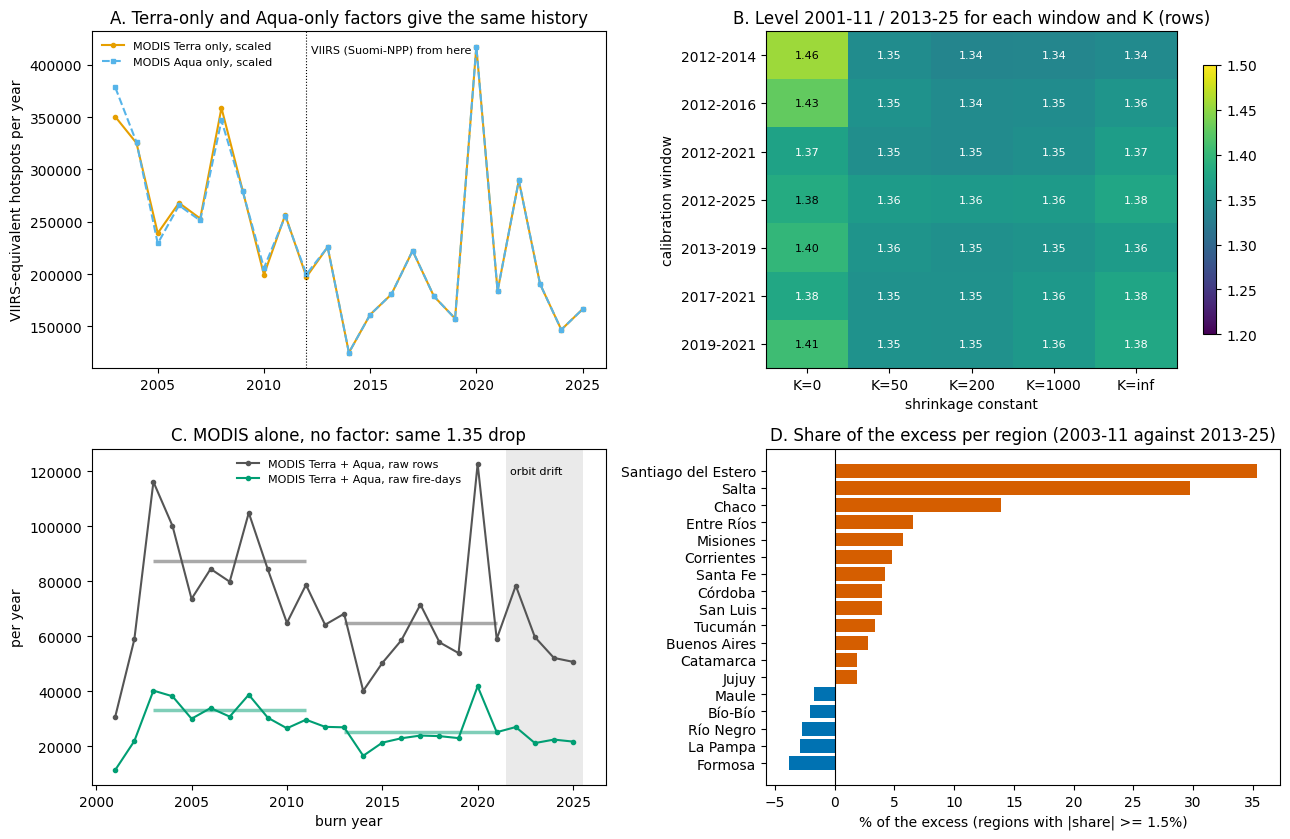

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
ax = axes[0, 0]
yrs = range(2003, 2026)
ax.plot(list(yrs), [A[('terra', 'rows')].get(y) for y in yrs], color='#E69F00', marker='o', ms=3, label='MODIS Terra only, scaled')
ax.plot(list(yrs), [A[('aqua', 'rows')].get(y) for y in yrs], color='#56B4E9', marker='s', ms=3, ls='--', label='MODIS Aqua only, scaled')
ax.axvline(2012, color='k', lw=0.8, ls=':')
ax.text(2012.2, ax.get_ylim()[1] * 0.97, 'VIIRS (Suomi-NPP) from here', fontsize=8, va='top')
ax.set(title='A. Terra-only and Aqua-only factors give the same history', ylabel='VIIRS-equivalent hotspots per year')
ax.legend(fontsize=8, frameon=False)

ax = axes[0, 1]
piv = B[B.unit == 'rows'].pivot_table(index='window', columns='K', values='level')
piv.columns = [('inf' if math.isinf(c) else int(c)) for c in piv.columns]
im = ax.imshow(piv.values, cmap='viridis', vmin=1.2, vmax=1.5, aspect='auto')
ax.set_xticks(range(len(piv.columns)), [f'K={c}' for c in piv.columns])
ax.set_yticks(range(len(piv.index)), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, f'{piv.values[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if piv.values[i, j] < 1.38 else 'black')
ax.set(title='B. Level 2001-11 / 2013-25 for each window and K (rows)', xlabel='shrinkage constant', ylabel='calibration window')
plt.colorbar(im, ax=ax, shrink=0.8)

ax = axes[1, 0]
x = rw.loc[2001:2025]
ax.plot(x.index, x[('rows', 'modis')], color='#555555', marker='o', ms=3, label='MODIS Terra + Aqua, raw rows')
ax.plot(x.index, x[('firedays', 'modis')], color='#009E73', marker='o', ms=3, label='MODIS Terra + Aqua, raw fire-days')
for (a, b), lab in [((2003, 2011), '2003-11'), ((2013, 2021), '2013-21')]:
    ax.hlines(x.loc[a:b, ('rows', 'modis')].mean(), a, b, color='#555555', lw=2.5, alpha=0.5)
    ax.hlines(x.loc[a:b, ('firedays', 'modis')].mean(), a, b, color='#009E73', lw=2.5, alpha=0.5)
ax.axvspan(2021.5, 2025.5, color='#cccccc', alpha=0.4, lw=0)
ax.text(2021.7, ax.get_ylim()[1] * 0.95, 'orbit drift', fontsize=8, va='top')
ax.set(title='C. MODIS alone, no factor: same 1.35 drop', ylabel='per year', xlabel='burn year')
ax.legend(fontsize=8, frameon=False)

ax = axes[1, 1]
top = g.sort_values('excess', ascending=False)
lab = top.index.get_level_values(1).str.replace('Región de |Región del |Región ', '', regex=True)
vals = top['share of excess %'].values
keep = (np.abs(vals) >= 1.5)
ax.barh(np.array(lab)[keep][::-1], vals[keep][::-1], color=np.where(vals[keep][::-1] > 0, '#D55E00', '#0072B2'))
ax.axvline(0, color='k', lw=0.8)
ax.set(title='D. Share of the excess per region (2003-11 against 2013-25)', xlabel='% of the excess (regions with |share| >= 1.5%)')
fig.tight_layout()
fig.savefig(ROOT / 'docs' / 'findings' / '03b-pre2012-level.png', dpi=120)
plt.show()